# Gaussian Process Suggestions

Fit on observations through `CURRENT_WEEK` to propose candidates for `NEXT_WEEK`. Use Expected Improvement with `sobol_lbfgs`: scrambled Sobol screening plus local candidate points, followed by L-BFGS-B polishing. Explicit overrides are listed in `HEURISTIC_CANDIDATES`. Kernels are configured per function via `KERNEL_NAMES_BY_FUNCTION`. Suggestions are model-based and are not guaranteed global optima or measured gains.

In [1]:
%matplotlib inline
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bayesian_bbo import CONFIG, FUNCTION_SPECS
from bayesian_bbo.data import save_predictions
from bayesian_bbo.history import load_weekly_history
from bayesian_bbo.kernels import make_comparison_kernels
from bayesian_bbo.optimisation import BayesianOptimizer, OptimisationConfig
from bayesian_bbo.submission import format_submission
from bayesian_bbo.visualisation import plot_gp_2d, plot_gp_slices

CURRENT_WEEK = 6
NEXT_WEEK = CURRENT_WEEK + 1
FUNCTION_IDS = tuple(FUNCTION_SPECS)
LENGTH_CAPS = CONFIG['length_caps']
ALPHA_VALUES = {1: 0.1, 2: 0.1, 3: 0.1, 4: 0.1, 5: 0.1, 6: 0.0, 7: 0.0, 8: 0.0}
KERNEL_NAMES_BY_FUNCTION = {
    1: 'Rational Quadratic',
    2: 'RBF',
    3: 'Rational Quadratic',
    4: 'Matérn 3/2',
    5: 'Rational Quadratic',
    6: 'Rational Quadratic',
    7: 'Matérn 3/2',
    8: 'Rational Quadratic',
}

data_candidates = [Path('../../data'), Path('data'), Path('../data')]
matches = [path.resolve() for path in data_candidates if (path / 'function_1').is_dir()]
if not matches:
    raise FileNotFoundError('Could not find the data directory from the notebook working directory.')
data_root = matches[0]
history = load_weekly_history(data_root, current_week=CURRENT_WEEK, function_ids=FUNCTION_IDS)
TRAINING_OBSERVATIONS = {
    function_id: observations.through_week(CURRENT_WEEK)
    for function_id, observations in history.observations.items()
}
XI_VALUES = {
    function_id: ALPHA_VALUES[function_id] * np.std(TRAINING_OBSERVATIONS[function_id].outputs)
    for function_id in FUNCTION_IDS
}
print(f'Training cutoff: week {CURRENT_WEEK}; exporting week {NEXT_WEEK}')
print(f'Configured candidate pool: {CONFIG["candidates"]:,} per function')
print(f'Data root: {data_root}')
print(f'Kernel map: {KERNEL_NAMES_BY_FUNCTION}')

Training cutoff: week 6; exporting week 7
Configured candidate pool: 1,000,000 per function
Data root: /home/pabloncho/repositories/bayesian-bbo/data
Kernel map: {1: 'Rational Quadratic', 2: 'RBF', 3: 'Rational Quadratic', 4: 'Matérn 3/2', 5: 'Rational Quadratic', 6: 'Rational Quadratic', 7: 'Matérn 3/2', 8: 'Rational Quadratic'}


## 1. Candidate selection

Fit each function using `KERNEL_NAMES_BY_FUNCTION` and `LENGTH_CAPS`. Functions in `HEURISTIC_CANDIDATES` are scored at their explicit coordinates via `predict()` (local heuristics, not optimizer-selected points); all other functions use Sobol screening and L-BFGS-B polishing for EI. The EI score at each chosen point uses $\xi=\alpha\,\mathrm{std}(y)$ and the current incumbent.

In [2]:
# Candidates for F1, F2, F3 computed via SpacePartitioningOptimizer using each function's
# NB06 kernel (RQ, RBF, RQ), min_region_points=4, trust_length=0.4, acquisition='ei',
# xi=0.1, use_rank_transform=True, candidates=2048, seed=42.
HEURISTIC_CANDIDATES = {
    1: (0.564405, 0.685288),
    2: (0.729659, 0.995987),
    3: (0.245071, 0.447022, 0.484866),
}
unknown_functions = set(HEURISTIC_CANDIDATES) - set(FUNCTION_IDS)
if unknown_functions:
    raise ValueError(f'Unsupported heuristic function IDs: {sorted(unknown_functions)}')

optimizers = {}
candidate_records = []
for function_id in FUNCTION_IDS:
    observations = TRAINING_OBSERVATIONS[function_id]
    kernel_name = KERNEL_NAMES_BY_FUNCTION[function_id]
    kernel = make_comparison_kernels(
        observations.dimension, LENGTH_CAPS[function_id],
    )[kernel_name]
    optimizer = BayesianOptimizer(
        observations,
        OptimisationConfig(
            budget=1, candidates=CONFIG['candidates'], kernel=kernel,
            xi=XI_VALUES[function_id], search_strategy='sobol_lbfgs',
        ),
    )
    if function_id in HEURISTIC_CANDIDATES:
        candidate = np.asarray(HEURISTIC_CANDIDATES[function_id], dtype=float)
        if (candidate.shape != (observations.dimension,) or not np.all(np.isfinite(candidate))
                or np.any((candidate < 0) | (candidate >= 1))):
            raise ValueError(f'Function {function_id}: invalid heuristic candidate')
        if np.any(np.all(observations.inputs == candidate, axis=1)):
            raise ValueError(f'Function {function_id}: heuristic point has already been evaluated')
        means, stds, scores = optimizer.predict(candidate.reshape(1, -1))
        mean, std, score = float(means[0]), float(stds[0]), float(scores[0])
        selection_method = 'local heuristic'
    else:
        candidate, mean, std, score = optimizer.suggest_with_prediction()
        selection_method = 'EI Sobol/L-BFGS search'
    if np.any(np.all(observations.inputs == candidate, axis=1)):
        raise ValueError(f'Function {function_id}: optimizer suggested an already evaluated input')
    optimizers[function_id] = optimizer
    candidate_records.append({
        'function_id': function_id,
        'kernel': kernel_name,
        'selection_method': selection_method,
        'alpha': ALPHA_VALUES[function_id],
        'xi': XI_VALUES[function_id],
        'candidate': tuple(candidate),
        'submission': format_submission(candidate),
        'expected_mean': mean,
        'expected_std': std,
        'expected_ei': score,
        'previous_best': observations.best_output,
    })
next_candidates = pd.DataFrame(candidate_records)
display(next_candidates)

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__alpha is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,function_id,kernel,selection_method,alpha,xi,candidate,submission,expected_mean,expected_std,expected_ei,previous_best
0,1,Rational Quadratic,local heuristic,0.1,0.000087,"(0.564405, 0.685288)",0.564405-0.685288,-0.000027,0.000060,5.096820e-07,0.000006
1,2,RBF,local heuristic,0.1,0.024657,"(0.729659, 0.995987)",0.729659-0.995987,0.579979,0.047652,7.616054e-04,0.638942
2,3,Rational Quadratic,local heuristic,0.1,0.007887,"(0.245071, 0.447022, 0.484866)",0.245071-0.447022-0.484866,-0.004825,0.013883,2.784448e-03,-0.005895
3,4,Matérn 3/2,EI Sobol/L-BFGS search,0.1,0.889418,"(0.388077, 0.398319, 0.448079, 0.476222)",0.388077-0.398319-0.448079-0.476222,0.037588,0.632607,1.559412e-03,0.687027
4,5,Rational Quadratic,EI Sobol/L-BFGS search,0.1,202.308123,"(0.999999, 0.999999, 0.999999, 0.999999)",0.999999-0.999999-0.999999-0.999999,7817.210410,120.668359,1.052583e+02,7525.788598
5,6,Rational Quadratic,EI Sobol/L-BFGS search,0.0,0.000000,"(0.462421, 0.326523, 0.541069, 0.826821, 0.242...",0.462421-0.326523-0.541069-0.826821-0.242243,-0.348088,0.058050,1.630984e-02,-0.332793
6,7,Matérn 3/2,EI Sobol/L-BFGS search,0.0,0.000000,"(0.0, 0.0, 0.266239, 0.307549, 0.309511, 0.79455)",0.000000-0.000000-0.266239-0.307549-0.309511-0...,2.368466,0.205407,2.854002e-02,2.515628
7,8,Rational Quadratic,EI Sobol/L-BFGS search,0.0,0.000000,"(0.078306, 0.248985, 0.058345, 0.354498, 0.725...",0.078306-0.248985-0.058345-0.354498-0.725652-0...,9.900741,0.152105,3.026350e-02,9.976219


## 2. GP diagnostics at the selected candidates

Markers use the optimizer-returned candidate mean, standard deviation, and EI. Slice curves are conditional one-coordinate views through the candidate, not projections over other coordinates.

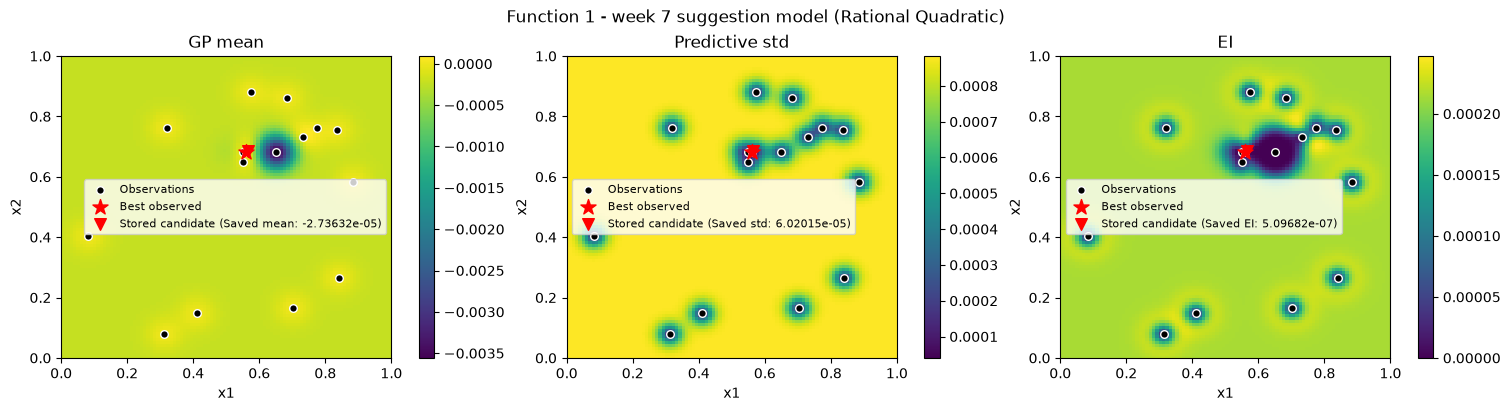

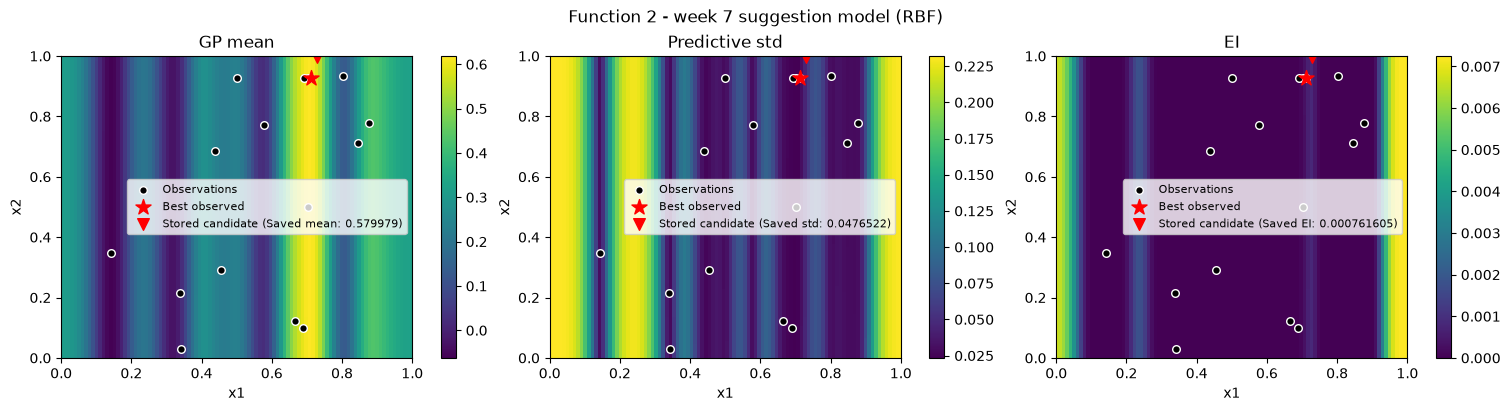

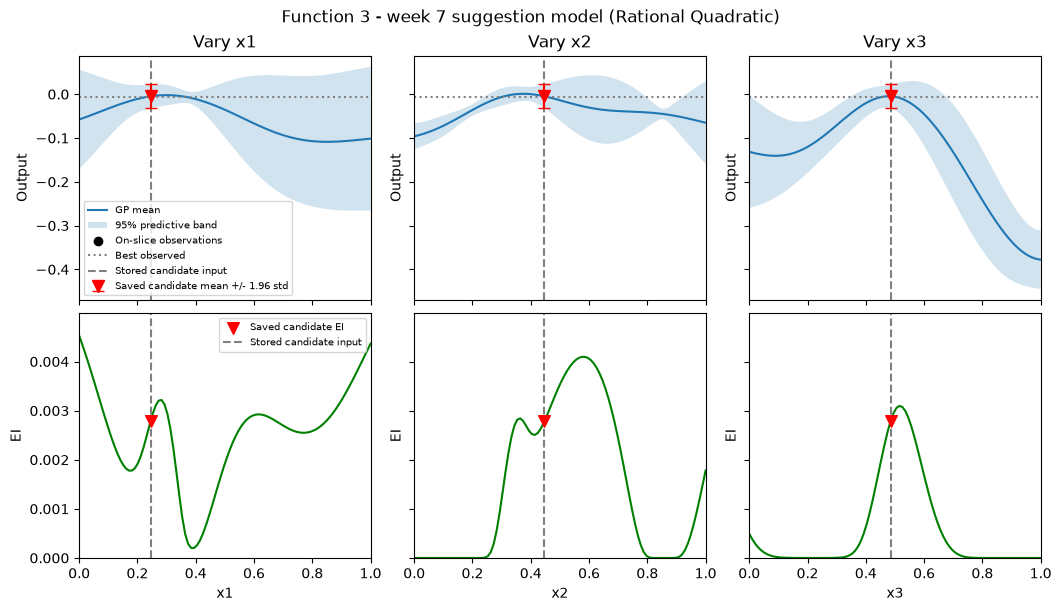

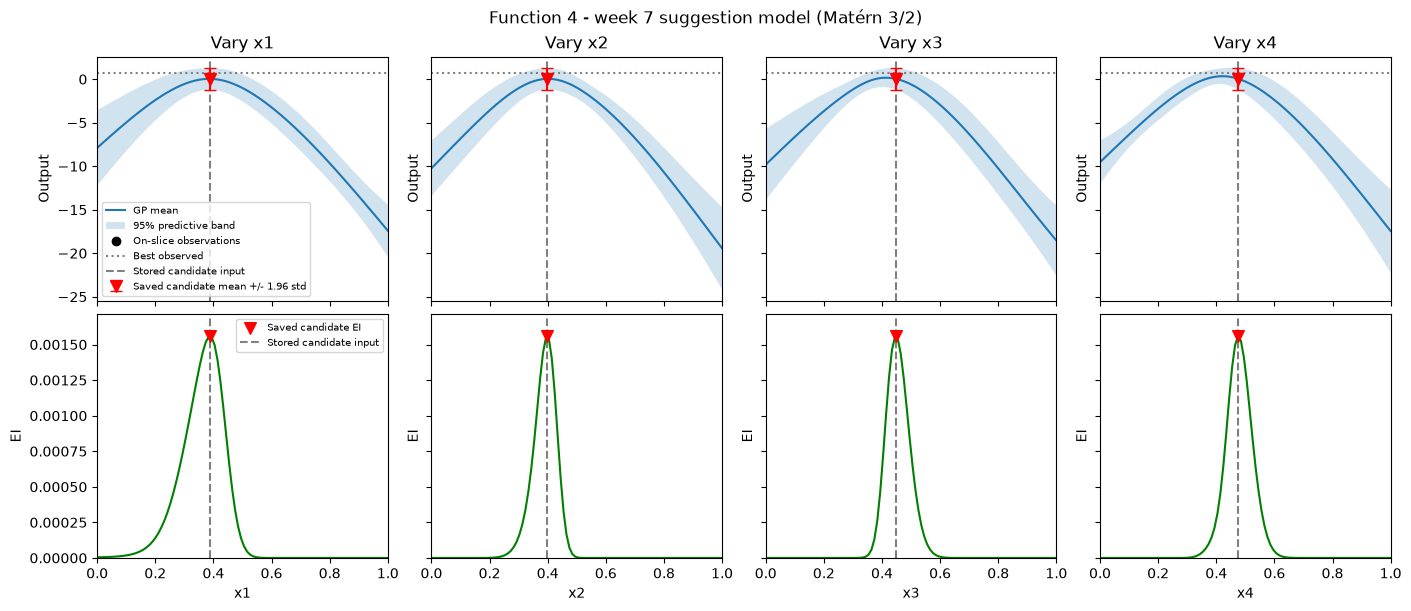

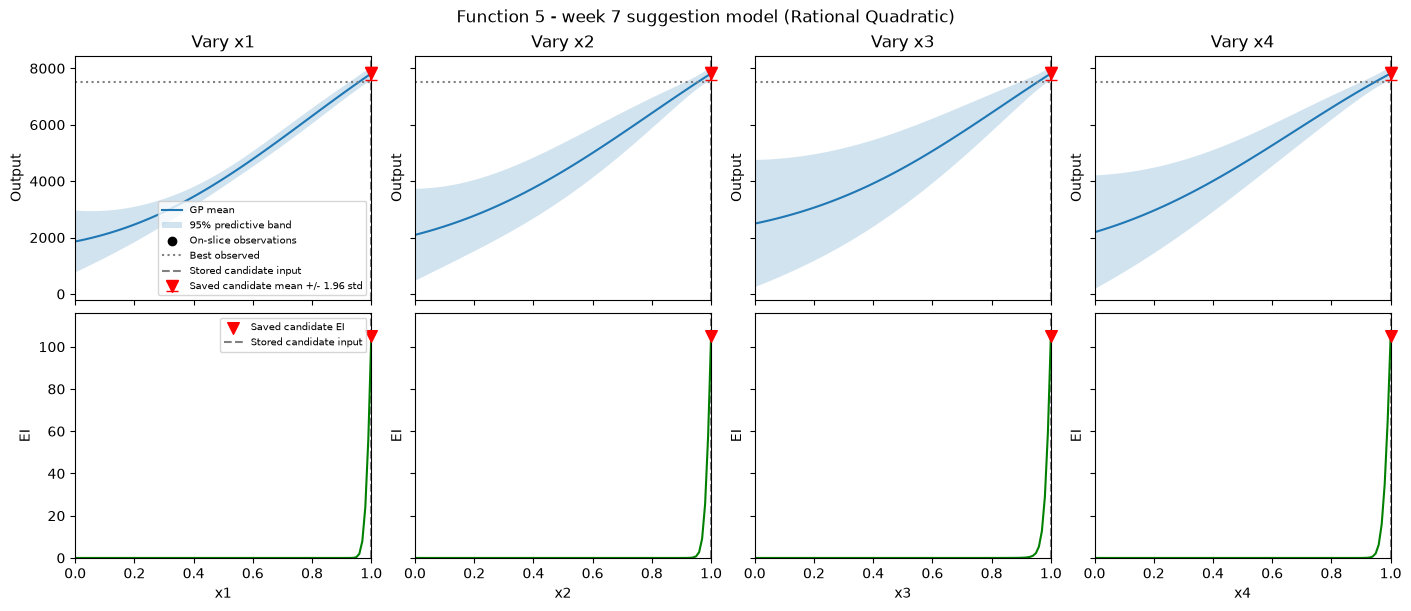

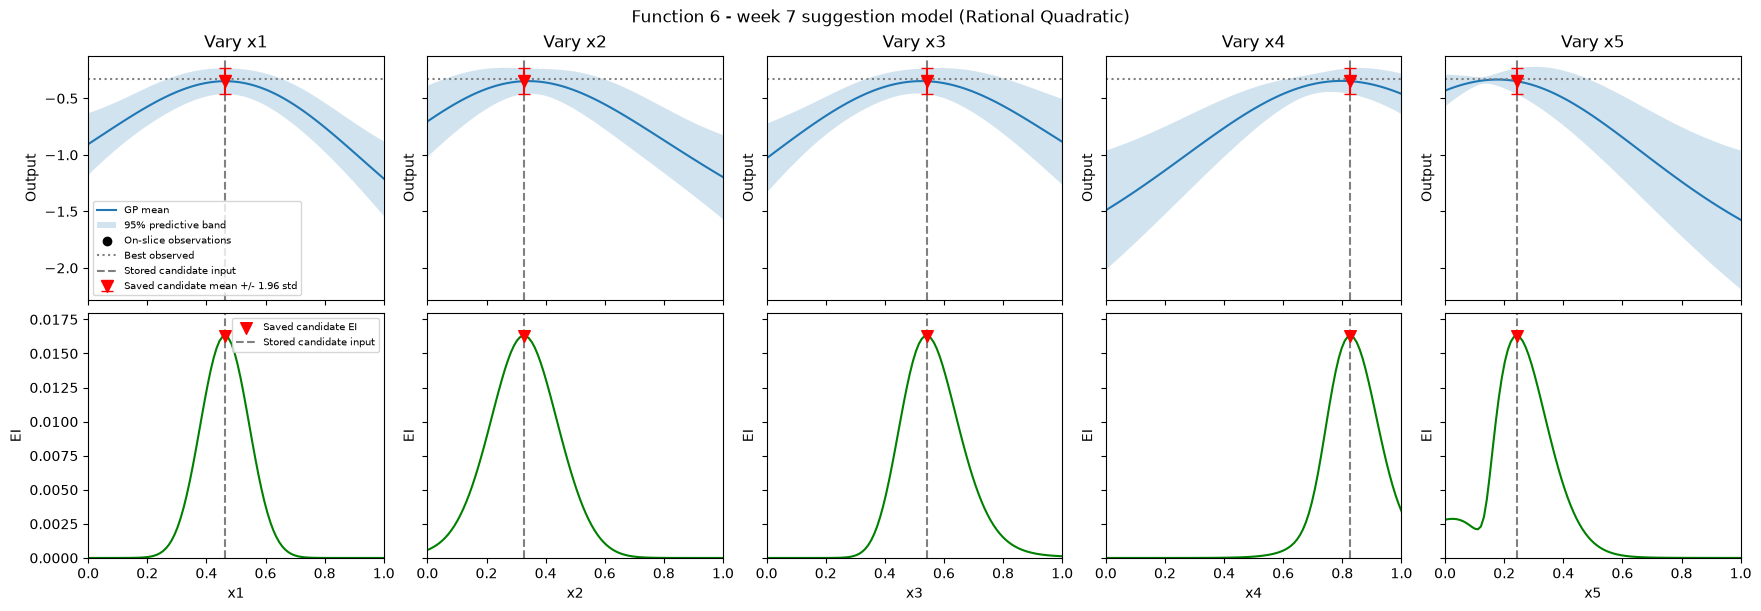

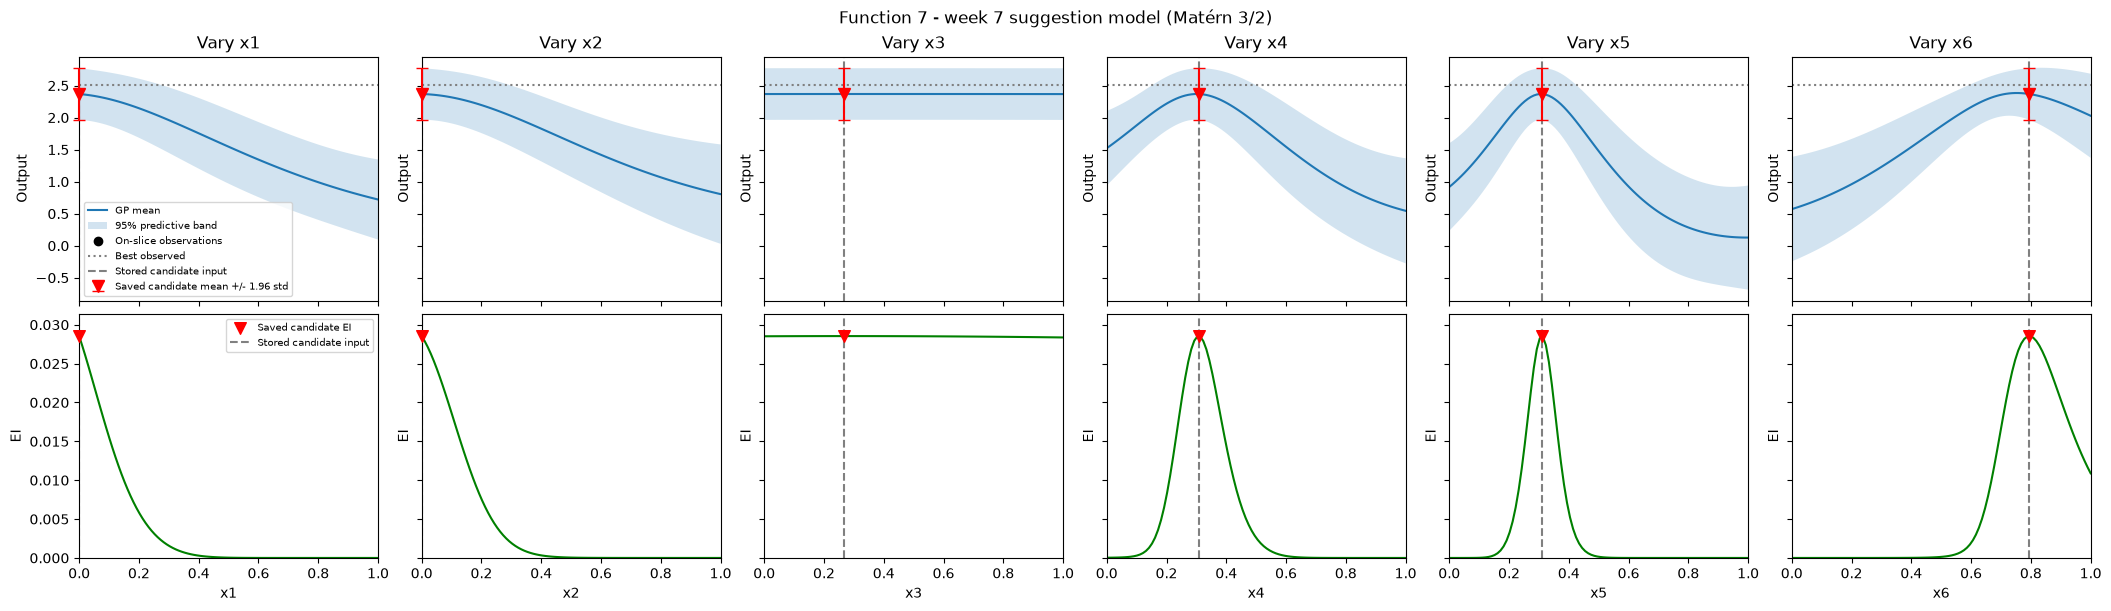

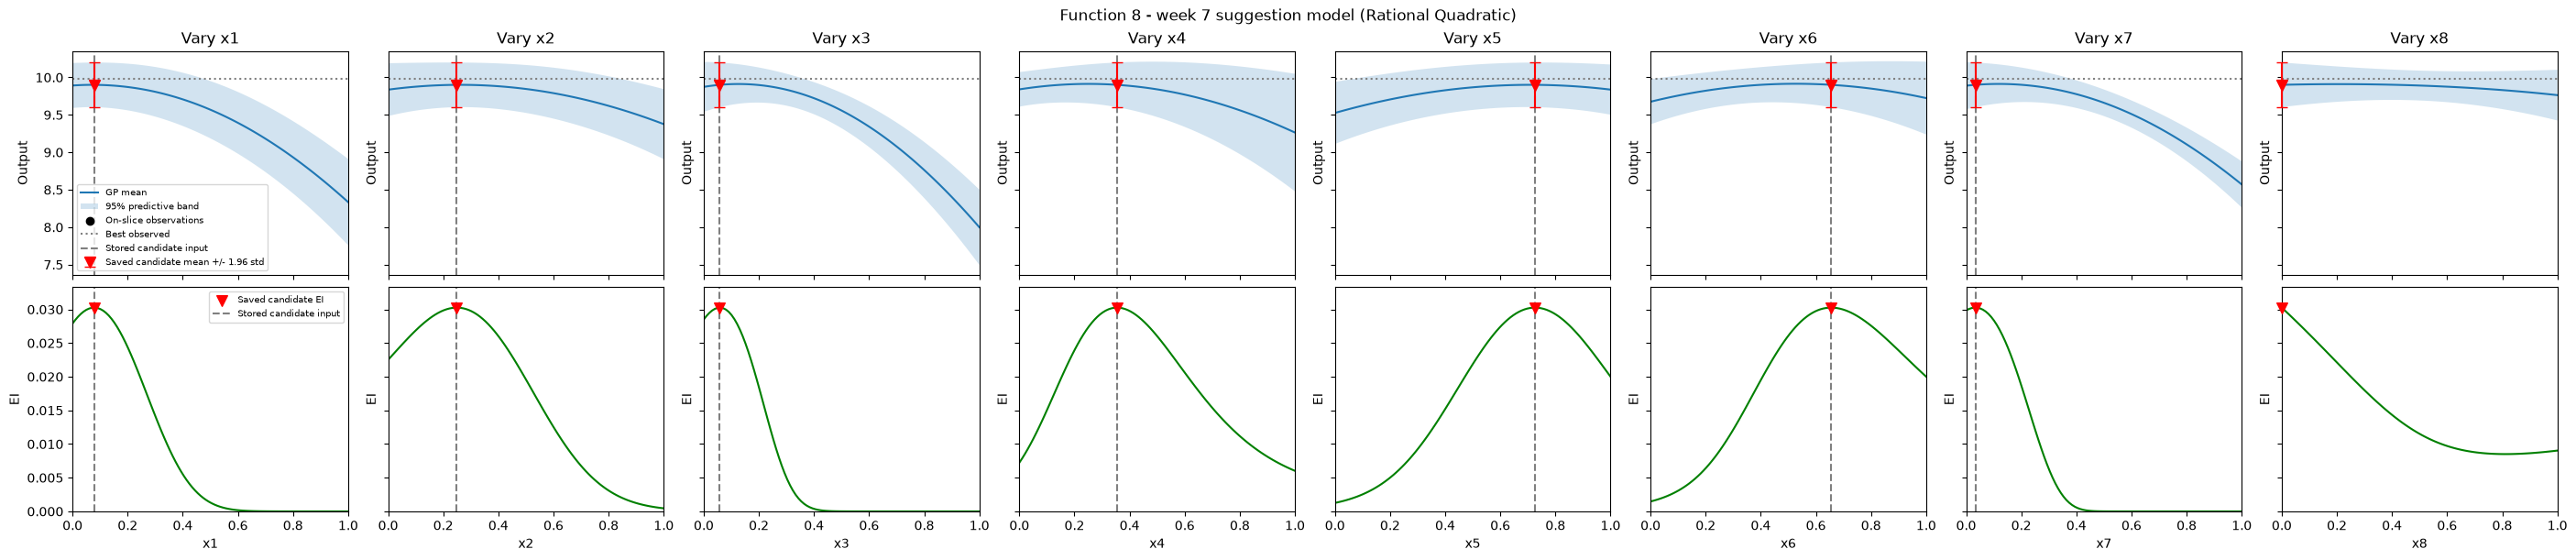

In [3]:
for row in candidate_records:
    function_id = row['function_id']
    observations = TRAINING_OBSERVATIONS[function_id]
    plot = plot_gp_2d if observations.dimension == 2 else plot_gp_slices
    figure, axes = plot(
        optimizers[function_id], n=100,
        candidate=row['candidate'],
        expected_mean=row['expected_mean'], expected_std=row['expected_std'],
        expected_ei=row['expected_ei'],
    )
    title = f'Function {function_id} - week {NEXT_WEEK} suggestion model ({row["kernel"]})'
    if observations.dimension == 2:
        grid_max = next((artist for artist in axes[2].collections
                         if artist.get_label() == 'Grid EI max'), None)
        if grid_max is not None:
            x1, x2 = grid_max.get_offsets()[0]
            title += f'\nGrid EI max: ({x1:.6f}, {x2:.6f})'
    figure.suptitle(title)
    display(figure)
    plt.close(figure)

## 3. Export next-week predictions

Save the six-decimal candidate coordinates and matching pre-evaluation mean, standard deviation, expected-best value, EI score, and incumbent settings to `data/weekly_updates/week_{NEXT_WEEK}/`. Existing differing exports are refused by default unless replacement is explicitly approved; earlier evaluated data remain unchanged.

In [4]:
export_rows = next_candidates.sort_values('function_id').reset_index(drop=True)
if export_rows.function_id.tolist() != list(FUNCTION_IDS):
    raise ValueError('Export requires exactly one candidate per function in function order.')

submission_points = export_rows[['function_id', 'submission']]
with pd.option_context('display.max_colwidth', None):
    display(submission_points)

suggested_points = [[float(value) for value in text.split('-')] for text in export_rows.submission]
if suggested_points != [list(point) for point in export_rows.candidate]:
    raise ValueError('Exported coordinates differ from the points used for predictions.')
best_outputs = [TRAINING_OBSERVATIONS[function_id].best_output for function_id in FUNCTION_IDS]

week_directory = data_root / 'weekly_updates' / f'week_{NEXT_WEEK}'
saved_prediction_paths = save_predictions(
    export_rows.expected_mean.tolist(),
    suggested_points,
    export_rows.expected_std.tolist(),
    best_outputs,
    week_directory,
    acquisition_scores=export_rows.expected_ei.tolist(),
    acquisition_settings=[
        {'name': 'ei', 'xi': float(xi), 'best': float(best)}
        for xi, best in zip(export_rows.xi, best_outputs)
    ],
)
saved_prediction_paths

,function_id,submission
0,1,0.564405-0.685288
1,2,0.729659-0.995987
2,3,0.245071-0.447022-0.484866
3,4,0.388077-0.398319-0.448079-0.476222
4,5,0.999999-0.999999-0.999999-0.999999
5,6,0.462421-0.326523-0.541069-0.826821-0.242243
6,7,0.000000-0.000000-0.266239-0.307549-0.309511-0.794550
7,8,0.078306-0.248985-0.058345-0.354498-0.725652-0.655225-0.033302-0.000000


Saved and verified /home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_7/inputs.json
Saved and verified /home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_7/predictions.json


{'inputs.json': PosixPath('/home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_7/inputs.json'),
 'predictions.json': PosixPath('/home/pabloncho/repositories/bayesian-bbo/data/weekly_updates/week_7/predictions.json')}